# Pharmaceutical Demand Forecasting

This notebook develops a machine learning based demand forecasting system
for pharmaceutical products using historical sales transaction data.

Objectives:
- Aggregate historical medicine demand
- Create time-based forecasting features
- Train and evaluate machine learning models
- Forecast future medicine demand
- Generate forecast outputs for inventory planning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(
    "../Data/Feature Engineered/sales_feature_engineered.csv"
)

df.head()

,order_id,order_date,customer_id,product_id,supplier_id,city,channel,quantity,unit_price,discount_pct,...,gross_sales,discount_amount,profit_margin_pct,revenue_per_unit,profit_per_unit,return_flag,high_discount,loss_order,revenue_category,order_size
0,ORD000001,2023-04-15,CUS024281,MED000014,SUP000211,Mumbai,Retail Pharmacy,3,505.20,12.15,...,1515.60,184.145400,-16.72,443.796667,-74.21,0.0,False,True,Low,Small
1,ORD000002,2024-01-14,CUS023216,MED000010,SUP000086,Hyderabad,Retail Pharmacy,17,2724.52,6.84,...,46316.84,3168.071856,49.82,2538.052353,1264.36,0.0,False,False,Medium,Small
2,ORD000003,2024-10-20,CUS007158,MED000016,SUP000083,Mumbai,hospital,11,1135.24,3.72,...,12487.64,464.540208,19.69,1092.963636,215.26,0.0,False,False,Low,Small
3,ORD000004,2020-01-04,CUS021793,MED000512,SUP000107,Mumbai,Hospital,51,392.29,0.00,...,20006.79,0.000000,23.80,392.290000,93.38,0.0,False,False,Low,Large
4,ORD000005,2024-03-17,CUS011808,MED001444,SUP000464,Delhi,Retail Pharmacy,4,3586.72,0.00,...,14346.88,0.000000,32.10,3586.720000,1151.40,0.0,False,False,Low,Small


In [3]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Date range:", df["order_date"].min(), "to", df["order_date"].max())
print("Unique medicines:", df["product_id"].nunique())

Shape: (190000, 32)
Columns: ['order_id', 'order_date', 'customer_id', 'product_id', 'supplier_id', 'city', 'channel', 'quantity', 'unit_price', 'discount_pct', 'revenue', 'profit', 'returned', 'return_reason', 'payment_method', 'year', 'quarter', 'month', 'month_name', 'day', 'day_name', 'week', 'gross_sales', 'discount_amount', 'profit_margin_pct', 'revenue_per_unit', 'profit_per_unit', 'return_flag', 'high_discount', 'loss_order', 'revenue_category', 'order_size']
Date range: 2020-01-01 to 2025-12-27
Unique medicines: 2500


In [4]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [5]:
df["order_date"].dtype

dtype('<M8[ns]')

In [6]:
monthly_demand = (
    df.groupby(
        [
            "product_id",
            pd.Grouper(key="order_date", freq="MS")
        ]
    )["quantity"]
    .sum()
    .reset_index()
)

In [7]:
monthly_demand.head()

,product_id,order_date,quantity
0,MED000001,2020-01-01,2100
1,MED000001,2020-02-01,2204
2,MED000001,2020-03-01,2442
3,MED000001,2020-04-01,1493
4,MED000001,2020-05-01,1663


In [8]:
monthly_demand.rename(
    columns={"quantity": "demand"},
    inplace=True
)

In [9]:
monthly_demand.head()

,product_id,order_date,demand
0,MED000001,2020-01-01,2100
1,MED000001,2020-02-01,2204
2,MED000001,2020-03-01,2442
3,MED000001,2020-04-01,1493
4,MED000001,2020-05-01,1663


In [10]:
monthly_demand["year"] = monthly_demand["order_date"].dt.year
monthly_demand["month"] = monthly_demand["order_date"].dt.month
monthly_demand["quarter"] = monthly_demand["order_date"].dt.quarter

In [11]:
monthly_demand["lag_1"] = (
    monthly_demand
    .groupby("product_id")["demand"]
    .shift(1)
)

monthly_demand["lag_2"] = (
    monthly_demand
    .groupby("product_id")["demand"]
    .shift(2)
)

monthly_demand["lag_3"] = (
    monthly_demand
    .groupby("product_id")["demand"]
    .shift(3)
)

In [12]:
monthly_demand["rolling_3"] = (
    monthly_demand
    .groupby("product_id")["demand"]
    .transform(
        lambda x: x.shift(1).rolling(3).mean()
    )
)

In [13]:
monthly_demand = monthly_demand.dropna().reset_index(drop=True)

In [14]:
print(monthly_demand.shape)
monthly_demand.head()

(54479, 10)


,product_id,order_date,demand,year,month,quarter,lag_1,lag_2,lag_3,rolling_3
0,MED000001,2020-04-01,1493,2020,4,2,2442.0,2204.0,2100.0,2248.666667
1,MED000001,2020-05-01,1663,2020,5,2,1493.0,2442.0,2204.0,2046.333333
2,MED000001,2020-06-01,1993,2020,6,2,1663.0,1493.0,2442.0,1866.000000
3,MED000001,2020-07-01,3082,2020,7,3,1993.0,1663.0,1493.0,1716.333333
4,MED000001,2020-08-01,4314,2020,8,3,3082.0,1993.0,1663.0,2246.000000


In [15]:
monthly_demand["order_date"].min(), monthly_demand["order_date"].max()

(Timestamp('2020-04-01 00:00:00'), Timestamp('2025-12-01 00:00:00'))

In [16]:
train = monthly_demand[
    monthly_demand["order_date"] < "2025-01-01"
].copy()

test = monthly_demand[
    monthly_demand["order_date"] >= "2025-01-01"
].copy()

print("Train shape:", train.shape)
print("Test shape:", test.shape)


Train shape: (44108, 10)
Test shape: (10371, 10)


In [17]:
features = [
    "year",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_3"
]

target = "demand"

In [18]:
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (44108, 7)
X_test: (10371, 7)


In [19]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [20]:
rf_pred = rf_model.predict(X_test)

In [21]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_pred
})

comparison.head(10)

,Actual,Predicted
0,2798,2183.474275
1,2418,2209.838968
2,1971,2306.509375
3,1572,1444.813430
4,999,1527.077722
5,2681,2352.570500
6,3622,3790.165658
7,3926,4642.124636
8,3988,3987.479283
9,2292,2641.544432


In [22]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Performance")
print("-------------------------")
print("MAE :", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²  :", round(rf_r2, 4))

Random Forest Performance
-------------------------
MAE : 40.01
RMSE: 87.67
R²  : 0.9542


In [23]:
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

gb_model.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.05
,n_estimators,200
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,5
,min_impurity_decrease,0.0
,init,None


In [24]:
gb_pred = gb_model.predict(X_test)

In [25]:
gb_mae = mean_absolute_error(y_test, gb_pred)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, gb_pred)
)

gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Performance")
print("-----------------------------")
print("MAE :", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))
print("R²  :", round(gb_r2, 4))

Gradient Boosting Performance
-----------------------------
MAE : 39.51
RMSE: 86.88
R²  : 0.9551


In [26]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        rf_rmse,
        gb_rmse
    ],
    "R2": [
        rf_r2,
        gb_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R2
0,Random Forest,40.014392,87.674054,0.954239
1,Gradient Boosting,39.512462,86.884594,0.955059


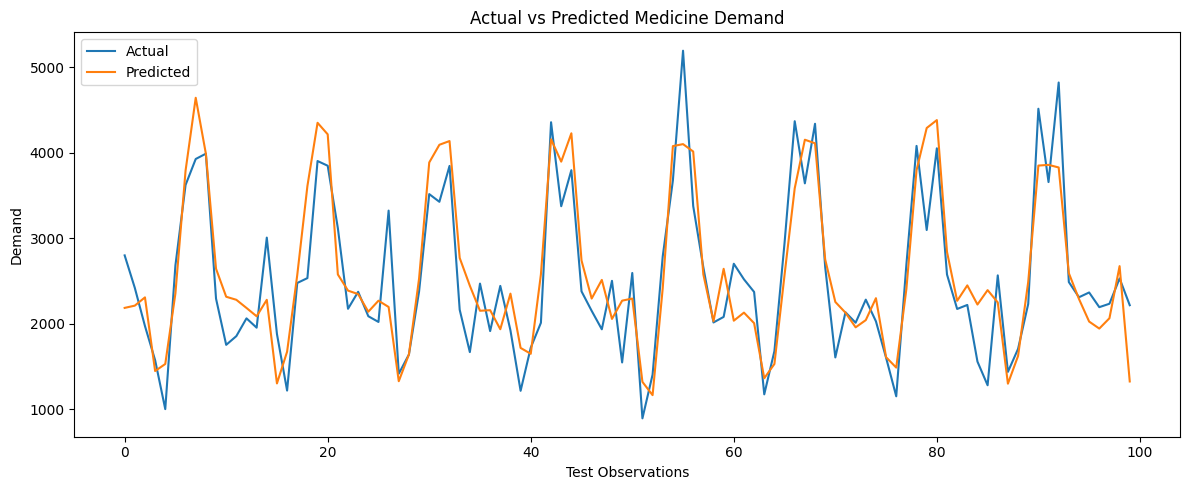

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values[:100],
    label="Actual"
)

plt.plot(
    rf_pred[:100],
    label="Predicted"
)

plt.title("Actual vs Predicted Medicine Demand")
plt.xlabel("Test Observations")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

In [29]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [30]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression")
print("-----------------")
print("MAE :", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("R²  :", round(lr_r2, 4))

Linear Regression
-----------------
MAE : 56.15
RMSE: 154.71
R²  : 0.8575


In [31]:
et_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train, y_train)

et_pred = et_model.predict(X_test)

In [32]:
et_mae = mean_absolute_error(y_test, et_pred)
et_rmse = np.sqrt(mean_squared_error(y_test, et_pred))
et_r2 = r2_score(y_test, et_pred)

print("Extra Trees")
print("-----------")
print("MAE :", round(et_mae, 2))
print("RMSE:", round(et_rmse, 2))
print("R²  :", round(et_r2, 4))

Extra Trees
-----------
MAE : 40.01
RMSE: 89.33
R²  : 0.9525


In [33]:
hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

hgb_model.fit(X_train, y_train)

hgb_pred = hgb_model.predict(X_test)

In [34]:
hgb_mae = mean_absolute_error(y_test, hgb_pred)
hgb_rmse = np.sqrt(mean_squared_error(y_test, hgb_pred))
hgb_r2 = r2_score(y_test, hgb_pred)

print("HistGradientBoosting")
print("--------------------")
print("MAE :", round(hgb_mae, 2))
print("RMSE:", round(hgb_rmse, 2))
print("R²  :", round(hgb_r2, 4))

HistGradientBoosting
--------------------
MAE : 40.39
RMSE: 86.88
R²  : 0.9551


In [35]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "Extra Trees",
        "HistGradientBoosting"
    ],
    "MAE": [
        lr_mae,
        rf_mae,
        gb_mae,
        et_mae,
        hgb_mae
    ],
    "RMSE": [
        lr_rmse,
        rf_rmse,
        gb_rmse,
        et_rmse,
        hgb_rmse
    ],
    "R2": [
        lr_r2,
        rf_r2,
        gb_r2,
        et_r2,
        hgb_r2
    ]
})

model_comparison.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

,Model,MAE,RMSE,R2
0,HistGradientBoosting,40.390426,86.883493,0.955060
1,Gradient Boosting,39.512462,86.884594,0.955059
2,Random Forest,40.014392,87.674054,0.954239
3,Extra Trees,40.005428,89.334425,0.952489
4,Linear Regression,56.150682,154.713062,0.857502


In [37]:
def calculate_mape(y_true, y_pred):
    mask = y_true != 0
    
    return np.mean(
        np.abs(
            (y_true[mask] - y_pred[mask]) /
            y_true[mask]
        )
    ) * 100

In [38]:
lr_mape = calculate_mape(y_test.values, lr_pred)
rf_mape = calculate_mape(y_test.values, rf_pred)
gb_mape = calculate_mape(y_test.values, gb_pred)
et_mape = calculate_mape(y_test.values, et_pred)
hgb_mape = calculate_mape(y_test.values, hgb_pred)

In [39]:
model_comparison["MAPE"] = [
    lr_mape,
    rf_mape,
    gb_mape,
    et_mape,
    hgb_mape
]

model_comparison = model_comparison.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

model_comparison

,Model,MAE,RMSE,R2,MAPE
0,HistGradientBoosting,40.390426,86.883493,0.955060,246.229336
1,Gradient Boosting,39.512462,86.884594,0.955059,228.520132
2,Random Forest,40.014392,87.674054,0.954239,233.166796
3,Extra Trees,40.005428,89.334425,0.952489,229.492286
4,Linear Regression,56.150682,154.713062,0.857502,271.097226


In [40]:
monthly_demand_enhanced = monthly_demand.copy()

monthly_demand_enhanced = monthly_demand_enhanced.sort_values(
    "order_date"
).reset_index(drop=True)

In [41]:
monthly_demand_enhanced["lag_6"] = (
    monthly_demand_enhanced["demand"].shift(6)
)

monthly_demand_enhanced["lag_12"] = (
    monthly_demand_enhanced["demand"].shift(12)
)

In [42]:
monthly_demand_enhanced["rolling_6"] = (
    monthly_demand_enhanced["demand"]
    .shift(1)
    .rolling(window=6)
    .mean()
)

monthly_demand_enhanced["rolling_12"] = (
    monthly_demand_enhanced["demand"]
    .shift(1)
    .rolling(window=12)
    .mean()
)

In [43]:
monthly_demand_enhanced[
    [
        "order_date",
        "demand",
        "lag_1",
        "lag_2",
        "lag_3",
        "lag_6",
        "lag_12",
        "rolling_3",
        "rolling_6",
        "rolling_12"
    ]
].head(15)

,order_date,demand,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_3,rolling_6,rolling_12
0,2020-04-01,1493,2442.0,2204.0,2100.0,NaN,NaN,2248.666667,NaN,NaN
1,2020-04-01,5,11.0,2.0,20.0,NaN,NaN,11.000000,NaN,NaN
2,2020-04-01,12,12.0,11.0,46.0,NaN,NaN,23.000000,NaN,NaN
3,2020-04-01,1138,2610.0,1284.0,994.0,NaN,NaN,1629.333333,NaN,NaN
4,2020-04-01,1527,2361.0,2700.0,2527.0,NaN,NaN,2529.333333,NaN,NaN
5,2020-04-01,27,26.0,73.0,30.0,NaN,NaN,43.000000,NaN,NaN
6,2020-04-01,3,13.0,3.0,16.0,1493.0,NaN,10.666667,700.333333,NaN
7,2020-04-01,63,21.0,33.0,18.0,5.0,NaN,24.000000,452.000000,NaN
8,2020-04-01,10,46.0,52.0,41.0,12.0,NaN,46.333333,461.666667,NaN
9,2020-04-01,23,35.0,12.0,10.0,1138.0,NaN,19.000000,461.333333,NaN


In [44]:
monthly_demand_enhanced = (
    monthly_demand_enhanced
    .dropna()
    .reset_index(drop=True)
)

In [45]:
print("Enhanced dataset shape:", monthly_demand_enhanced.shape)

print(
    monthly_demand_enhanced[
        [
            "lag_6",
            "lag_12",
            "rolling_6",
            "rolling_12"
        ]
    ].isnull().sum()
)

Enhanced dataset shape: (54467, 14)
lag_6         0
lag_12        0
rolling_6     0
rolling_12    0
dtype: int64


In [46]:
train_enhanced = monthly_demand_enhanced[
    monthly_demand_enhanced["order_date"] < "2025-01-01"
].copy()

test_enhanced = monthly_demand_enhanced[
    monthly_demand_enhanced["order_date"] >= "2025-01-01"
].copy()

print("Train shape:", train_enhanced.shape)
print("Test shape :", test_enhanced.shape)

print(
    "\nTrain dates:",
    train_enhanced["order_date"].min(),
    "to",
    train_enhanced["order_date"].max()
)

print(
    "Test dates :",
    test_enhanced["order_date"].min(),
    "to",
    test_enhanced["order_date"].max()
)

Train shape: (44096, 14)
Test shape : (10371, 14)

Train dates: 2020-04-01 00:00:00 to 2024-12-01 00:00:00
Test dates : 2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [47]:
enhanced_features = [
    "year",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_3",
    "rolling_6",
    "rolling_12"
]

target = "demand"

In [48]:
X_train_enhanced = train_enhanced[enhanced_features]
y_train_enhanced = train_enhanced[target]

X_test_enhanced = test_enhanced[enhanced_features]
y_test_enhanced = test_enhanced[target]

print("X_train:", X_train_enhanced.shape)
print("X_test :", X_test_enhanced.shape)

X_train: (44096, 11)
X_test : (10371, 11)


In [49]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    )
}

In [50]:
results = []

predictions = {}

for name, model in models.items():

    # Train
    model.fit(
        X_train_enhanced,
        y_train_enhanced
    )

    # Predict
    pred = model.predict(
        X_test_enhanced
    )

    predictions[name] = pred

    # Metrics
    mae = mean_absolute_error(
        y_test_enhanced,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_enhanced,
            pred
        )
    )

    r2 = r2_score(
        y_test_enhanced,
        pred
    )

    y_actual = y_test_enhanced.to_numpy()

    non_zero = y_actual != 0

    mape = np.mean(
        np.abs(
            (y_actual[non_zero] - pred[non_zero])
            / y_actual[non_zero]
        )
    ) * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    })

In [51]:
enhanced_comparison = pd.DataFrame(results)

enhanced_comparison = enhanced_comparison.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

enhanced_comparison

,Model,MAE,RMSE,R2,MAPE
0,HistGradientBoosting,39.177656,83.746024,0.958247,234.798185
1,Random Forest,39.379563,85.422249,0.956559,231.387104
2,Extra Trees,39.581858,86.260683,0.955702,230.174845
3,Gradient Boosting,39.279533,86.527874,0.955427,228.670608
4,Linear Regression,56.231824,154.818245,0.857308,269.552499


In [52]:
enhanced_comparison_display = enhanced_comparison.copy()

enhanced_comparison_display[
    ["MAE", "RMSE", "R2", "MAPE"]
] = enhanced_comparison_display[
    ["MAE", "RMSE", "R2", "MAPE"]
].round(2)

enhanced_comparison_display

,Model,MAE,RMSE,R2,MAPE
0,HistGradientBoosting,39.18,83.75,0.96,234.80
1,Random Forest,39.38,85.42,0.96,231.39
2,Extra Trees,39.58,86.26,0.96,230.17
3,Gradient Boosting,39.28,86.53,0.96,228.67
4,Linear Regression,56.23,154.82,0.86,269.55


In [53]:
best_model_name = enhanced_comparison.iloc[0]["Model"]

best_model = models[best_model_name]

print("FINAL BEST MODEL")
print("=================")
print(best_model_name)

print("\nPerformance:")
print(
    enhanced_comparison.iloc[0]
)

FINAL BEST MODEL
HistGradientBoosting

Performance:
Model    HistGradientBoosting
MAE                 39.177656
RMSE                83.746024
R2                   0.958247
MAPE               234.798185
Name: 0, dtype: object


In [54]:
old_best_rmse = model_comparison.iloc[0]["RMSE"]
new_best_rmse = enhanced_comparison.iloc[0]["RMSE"]

improvement = (
    (old_best_rmse - new_best_rmse)
    / old_best_rmse
) * 100

print("Previous Best RMSE :", round(old_best_rmse, 2))
print("Enhanced Best RMSE :", round(new_best_rmse, 2))
print("RMSE Improvement   :", round(improvement, 2), "%")

Previous Best RMSE : 86.88
Enhanced Best RMSE : 83.75
RMSE Improvement   : 3.61 %


In [55]:
enhanced_comparison_display

,Model,MAE,RMSE,R2,MAPE
0,HistGradientBoosting,39.18,83.75,0.96,234.80
1,Random Forest,39.38,85.42,0.96,231.39
2,Extra Trees,39.58,86.26,0.96,230.17
3,Gradient Boosting,39.28,86.53,0.96,228.67
4,Linear Regression,56.23,154.82,0.86,269.55


In [56]:
print("FINAL BEST MODEL")
print(best_model_name)

FINAL BEST MODEL
HistGradientBoosting


In [57]:
final_features = [
    "year",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_3",
    "rolling_6",
    "rolling_12"
]

final_data = monthly_demand_enhanced.copy()

print("Final data shape:", final_data.shape)
print("Date range:")
print(final_data["order_date"].min(), "to", final_data["order_date"].max())

Final data shape: (54467, 14)
Date range:
2020-04-01 00:00:00 to 2025-12-01 00:00:00


In [58]:
X_final = final_data[final_features]
y_final = final_data["demand"]

print("X_final shape:", X_final.shape)
print("y_final shape:", y_final.shape)

X_final shape: (54467, 11)
y_final shape: (54467,)


In [59]:
final_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

final_model.fit(
    X_final,
    y_final
)

print("Final HistGradientBoosting model trained successfully.")

Final HistGradientBoosting model trained successfully.


In [60]:
forecast_history = final_data[
    ["order_date", "demand"]
].copy()

forecast_history = forecast_history.sort_values(
    "order_date"
).reset_index(drop=True)

print("Historical data:")
print(
    forecast_history[
        ["order_date", "demand"]
    ].tail(15)
)

Historical data:
      order_date  demand
54452 2025-12-01      14
54453 2025-12-01      28
54454 2025-12-01      72
54455 2025-12-01      12
54456 2025-12-01     111
54457 2025-12-01     158
54458 2025-12-01       9
54459 2025-12-01      15
54460 2025-12-01       6
54461 2025-12-01     103
54462 2025-12-01      94
54463 2025-12-01    1798
54464 2025-12-01       4
54465 2025-12-01      37
54466 2025-12-01      18


In [61]:
future_dates = pd.date_range(
    start="2026-01-01",
    end="2026-12-01",
    freq="MS"
)

print("Number of forecast months:", len(future_dates))
print(future_dates)

Number of forecast months: 12
DatetimeIndex(['2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01',
               '2026-05-01', '2026-06-01', '2026-07-01', '2026-08-01',
               '2026-09-01', '2026-10-01', '2026-11-01', '2026-12-01'],
              dtype='datetime64[ns]', freq='MS')


In [62]:
forecast_history = forecast_history.copy()

future_predictions = []

for current_date in future_dates:

    # Previous demand values
    lag_1 = forecast_history["demand"].iloc[-1]

    lag_2 = forecast_history["demand"].iloc[-2]

    lag_3 = forecast_history["demand"].iloc[-3]

    lag_6 = forecast_history["demand"].iloc[-6]

    lag_12 = forecast_history["demand"].iloc[-12]

    # Rolling averages using only previous demand
    rolling_3 = (
        forecast_history["demand"]
        .iloc[-3:]
        .mean()
    )

    rolling_6 = (
        forecast_history["demand"]
        .iloc[-6:]
        .mean()
    )

    rolling_12 = (
        forecast_history["demand"]
        .iloc[-12:]
        .mean()
    )

    # Create feature row
    future_features = pd.DataFrame({
        "year": [current_date.year],
        "month": [current_date.month],
        "quarter": [current_date.quarter],
        "lag_1": [lag_1],
        "lag_2": [lag_2],
        "lag_3": [lag_3],
        "lag_6": [lag_6],
        "lag_12": [lag_12],
        "rolling_3": [rolling_3],
        "rolling_6": [rolling_6],
        "rolling_12": [rolling_12]
    })

    # Predict current month
    prediction = final_model.predict(
        future_features[final_features]
    )[0]

    # Store prediction
    future_predictions.append(prediction)

    # Add prediction to history
    forecast_history = pd.concat(
        [
            forecast_history,
            pd.DataFrame({
                "order_date": [current_date],
                "demand": [prediction]
            })
        ],
        ignore_index=True
    )

In [63]:
forecast_2026 = pd.DataFrame({
    "order_date": future_dates,
    "predicted_demand": future_predictions
})

forecast_2026

,order_date,predicted_demand
0,2026-01-01,40.771545
1,2026-02-01,40.771545
2,2026-03-01,40.771545
3,2026-04-01,40.771545
4,2026-05-01,40.771545
5,2026-06-01,41.222369
6,2026-07-01,41.222369
7,2026-08-01,41.222369
8,2026-09-01,41.222369
9,2026-10-01,40.781375


In [64]:
forecast_2026["predicted_demand"] = (
    forecast_2026["predicted_demand"]
    .round(0)
    .astype(int)
)

forecast_2026

,order_date,predicted_demand
0,2026-01-01,41
1,2026-02-01,41
2,2026-03-01,41
3,2026-04-01,41
4,2026-05-01,41
5,2026-06-01,41
6,2026-07-01,41
7,2026-08-01,41
8,2026-09-01,41
9,2026-10-01,41


In [65]:
total_2026_demand = forecast_2026[
    "predicted_demand"
].sum()

average_monthly_demand = forecast_2026[
    "predicted_demand"
].mean()

print("Total Predicted Demand for 2026:", total_2026_demand)
print("Average Monthly Predicted Demand:", round(average_monthly_demand, 2))

Total Predicted Demand for 2026: 492
Average Monthly Predicted Demand: 41.0


In [66]:
highest_month = forecast_2026.loc[
    forecast_2026["predicted_demand"].idxmax()
]

lowest_month = forecast_2026.loc[
    forecast_2026["predicted_demand"].idxmin()
]

print("Highest Demand Month:")
print(highest_month)

print("\nLowest Demand Month:")
print(lowest_month)

Highest Demand Month:
order_date          2026-01-01 00:00:00
predicted_demand                     41
Name: 0, dtype: object

Lowest Demand Month:
order_date          2026-01-01 00:00:00
predicted_demand                     41
Name: 0, dtype: object


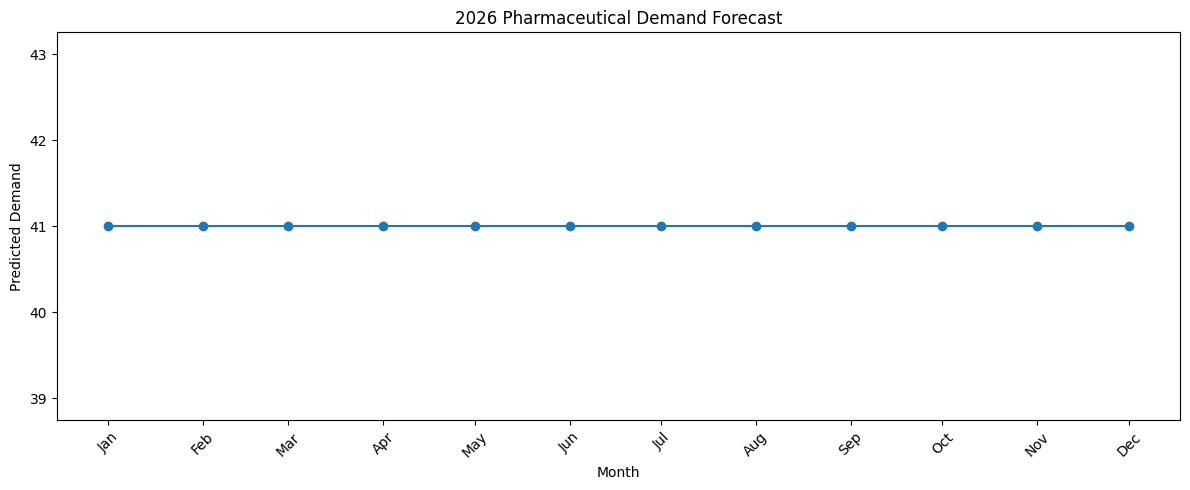

In [67]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_2026["order_date"],
    forecast_2026["predicted_demand"],
    marker="o"
)

plt.title("2026 Pharmaceutical Demand Forecast")
plt.xlabel("Month")
plt.ylabel("Predicted Demand")
plt.xticks(
    forecast_2026["order_date"],
    forecast_2026["order_date"].dt.strftime("%b"),
    rotation=45
)

plt.tight_layout()
plt.show()

In [71]:
print("Last 24 historical demand values:")
print(
    forecast_history[
        ["order_date", "demand"]
    ].tail(24).to_string(index=False)
)

Last 24 historical demand values:
order_date      demand
2025-12-01   12.000000
2025-12-01  111.000000
2025-12-01  158.000000
2025-12-01    9.000000
2025-12-01   15.000000
2025-12-01    6.000000
2025-12-01  103.000000
2025-12-01   94.000000
2025-12-01 1798.000000
2025-12-01    4.000000
2025-12-01   37.000000
2025-12-01   18.000000
2026-01-01   40.771545
2026-02-01   40.771545
2026-03-01   40.771545
2026-04-01   40.771545
2026-05-01   40.771545
2026-06-01   41.222369
2026-07-01   41.222369
2026-08-01   41.222369
2026-09-01   41.222369
2026-10-01   40.781375
2026-11-01   40.781375
2026-12-01   40.781375


In [68]:
actual_2025 = final_data[
    final_data["order_date"].dt.year == 2025
][
    ["order_date", "demand"]
].copy()

print(actual_2025.to_string(index=False))

order_date  demand
2025-01-01      13
2025-01-01       7
2025-01-01     162
2025-01-01      35
2025-01-01      50
2025-01-01       3
2025-01-01       8
2025-01-01      58
2025-01-01       8
2025-01-01      38
2025-01-01      40
2025-01-01     138
2025-01-01       4
2025-01-01      62
2025-01-01      43
2025-01-01       6
2025-01-01     205
2025-01-01      13
2025-01-01       4
2025-01-01      57
2025-01-01       5
2025-01-01    2331
2025-01-01    2275
2025-01-01      96
2025-01-01     143
2025-01-01      90
2025-01-01      11
2025-01-01       8
2025-01-01       5
2025-01-01      58
2025-01-01     128
2025-01-01      50
2025-01-01      56
2025-01-01     123
2025-01-01      37
2025-01-01       7
2025-01-01      10
2025-01-01      66
2025-01-01       9
2025-01-01      12
2025-01-01       6
2025-01-01      92
2025-01-01       8
2025-01-01      26
2025-01-01      10
2025-01-01      49
2025-01-01       4
2025-01-01      25
2025-01-01      38
2025-01-01      44
2025-01-01      62
2025-01-01  

In [69]:
print(
    pd.DataFrame({
        "Month": future_dates,
        "Raw_Prediction": future_predictions
    }).to_string(index=False)
)

     Month  Raw_Prediction
2026-01-01       40.771545
2026-02-01       40.771545
2026-03-01       40.771545
2026-04-01       40.771545
2026-05-01       40.771545
2026-06-01       41.222369
2026-07-01       41.222369
2026-08-01       41.222369
2026-09-01       41.222369
2026-10-01       40.781375
2026-11-01       40.781375
2026-12-01       40.781375


In [70]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    final_model,
    X_test_enhanced,
    y_test_enhanced,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

feature_importance = pd.DataFrame({
    "Feature": final_features,
    "Importance": perm_result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,lag_1,376.040005
1,lag_3,245.506756
2,month,126.599018
3,rolling_3,9.466109
4,rolling_6,6.980499
5,lag_2,6.177033
6,lag_12,4.546684
7,lag_6,4.534219
8,rolling_12,4.521533
9,quarter,0.000000


In [72]:
print("monthly_demand columns:")
print(monthly_demand.columns.tolist())

monthly_demand columns:
['product_id', 'order_date', 'demand', 'year', 'month', 'quarter', 'lag_1', 'lag_2', 'lag_3', 'rolling_3']


In [73]:
print("Original df columns:")
print(df.columns.tolist())

Original df columns:
['order_id', 'order_date', 'customer_id', 'product_id', 'supplier_id', 'city', 'channel', 'quantity', 'unit_price', 'discount_pct', 'revenue', 'profit', 'returned', 'return_reason', 'payment_method', 'year', 'quarter', 'month', 'month_name', 'day', 'day_name', 'week', 'gross_sales', 'discount_amount', 'profit_margin_pct', 'revenue_per_unit', 'profit_per_unit', 'return_flag', 'high_discount', 'loss_order', 'revenue_category', 'order_size']


In [74]:
print(monthly_demand.head(10).to_string())

  product_id order_date  demand  year  month  quarter   lag_1   lag_2   lag_3    rolling_3
0  MED000001 2020-04-01    1493  2020      4        2  2442.0  2204.0  2100.0  2248.666667
1  MED000001 2020-05-01    1663  2020      5        2  1493.0  2442.0  2204.0  2046.333333
2  MED000001 2020-06-01    1993  2020      6        2  1663.0  1493.0  2442.0  1866.000000
3  MED000001 2020-07-01    3082  2020      7        3  1993.0  1663.0  1493.0  1716.333333
4  MED000001 2020-08-01    4314  2020      8        3  3082.0  1993.0  1663.0  2246.000000
5  MED000001 2020-09-01    4475  2020      9        3  4314.0  3082.0  1993.0  3129.666667
6  MED000001 2020-10-01    2404  2020     10        4  4475.0  4314.0  3082.0  3957.000000
7  MED000001 2020-11-01    2072  2020     11        4  2404.0  4475.0  4314.0  3731.000000
8  MED000001 2020-12-01    2543  2020     12        4  2072.0  2404.0  4475.0  2983.666667
9  MED000001 2021-01-01    3033  2021      1        1  2543.0  2072.0  2404.0  2339.666667

In [75]:
monthly_product = (
    df.groupby(
        ["product_id", pd.Grouper(key="order_date", freq="MS")]
    )["quantity"]
    .sum()
    .reset_index()
    .rename(columns={"quantity": "demand"})
)

monthly_product = monthly_product.sort_values(
    ["product_id", "order_date"]
).reset_index(drop=True)

print("Shape:", monthly_product.shape)
print(monthly_product.head(10))

Shape: (61979, 3)
  product_id order_date  demand
0  MED000001 2020-01-01    2100
1  MED000001 2020-02-01    2204
2  MED000001 2020-03-01    2442
3  MED000001 2020-04-01    1493
4  MED000001 2020-05-01    1663
5  MED000001 2020-06-01    1993
6  MED000001 2020-07-01    3082
7  MED000001 2020-08-01    4314
8  MED000001 2020-09-01    4475
9  MED000001 2020-10-01    2404


In [76]:
print(
    monthly_product[
        ["product_id", "order_date", "demand"]
    ].head(20).to_string(index=False)
)

product_id order_date  demand
 MED000001 2020-01-01    2100
 MED000001 2020-02-01    2204
 MED000001 2020-03-01    2442
 MED000001 2020-04-01    1493
 MED000001 2020-05-01    1663
 MED000001 2020-06-01    1993
 MED000001 2020-07-01    3082
 MED000001 2020-08-01    4314
 MED000001 2020-09-01    4475
 MED000001 2020-10-01    2404
 MED000001 2020-11-01    2072
 MED000001 2020-12-01    2543
 MED000001 2021-01-01    3033
 MED000001 2021-02-01    2291
 MED000001 2021-03-01    1550
 MED000001 2021-04-01    1607
 MED000001 2021-05-01    1535
 MED000001 2021-06-01    2491
 MED000001 2021-07-01    3735
 MED000001 2021-08-01    4212


In [77]:
monthly_product["year"] = (
    monthly_product["order_date"].dt.year
)

monthly_product["month"] = (
    monthly_product["order_date"].dt.month
)

monthly_product["quarter"] = (
    monthly_product["order_date"].dt.quarter
)

In [78]:
monthly_product["lag_1"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .shift(1)
)

monthly_product["lag_2"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .shift(2)
)

monthly_product["lag_3"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .shift(3)
)

monthly_product["lag_6"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .shift(6)
)

monthly_product["lag_12"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .shift(12)
)

In [79]:
monthly_product["rolling_3"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .transform(
        lambda x: x.shift(1).rolling(3).mean()
    )
)

monthly_product["rolling_6"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .transform(
        lambda x: x.shift(1).rolling(6).mean()
    )
)

monthly_product["rolling_12"] = (
    monthly_product
    .groupby("product_id")["demand"]
    .transform(
        lambda x: x.shift(1).rolling(12).mean()
    )
)

In [80]:
check_product = (
    monthly_product[
        monthly_product["product_id"] == "MED000001"
    ]
    [
        [
            "product_id",
            "order_date",
            "demand",
            "lag_1",
            "lag_2",
            "lag_3",
            "lag_6",
            "lag_12",
            "rolling_3",
            "rolling_6",
            "rolling_12"
        ]
    ]
    .head(15)
)

print(check_product.to_string(index=False))

product_id order_date  demand  lag_1  lag_2  lag_3  lag_6  lag_12   rolling_3   rolling_6  rolling_12
 MED000001 2020-01-01    2100    NaN    NaN    NaN    NaN     NaN         NaN         NaN         NaN
 MED000001 2020-02-01    2204 2100.0    NaN    NaN    NaN     NaN         NaN         NaN         NaN
 MED000001 2020-03-01    2442 2204.0 2100.0    NaN    NaN     NaN         NaN         NaN         NaN
 MED000001 2020-04-01    1493 2442.0 2204.0 2100.0    NaN     NaN 2248.666667         NaN         NaN
 MED000001 2020-05-01    1663 1493.0 2442.0 2204.0    NaN     NaN 2046.333333         NaN         NaN
 MED000001 2020-06-01    1993 1663.0 1493.0 2442.0    NaN     NaN 1866.000000         NaN         NaN
 MED000001 2020-07-01    3082 1993.0 1663.0 1493.0 2100.0     NaN 1716.333333 1982.500000         NaN
 MED000001 2020-08-01    4314 3082.0 1993.0 1663.0 2204.0     NaN 2246.000000 2146.166667         NaN
 MED000001 2020-09-01    4475 4314.0 3082.0 1993.0 2442.0     NaN 3129.666667 2497

In [81]:
model_data = monthly_product.dropna().copy()

model_data = model_data.reset_index(drop=True)

print("Model data shape:", model_data.shape)
print("Products:", model_data["product_id"].nunique())
print(
    "Date range:",
    model_data["order_date"].min(),
    "to",
    model_data["order_date"].max()
)

Model data shape: (31979, 14)
Products: 2499
Date range: 2021-01-01 00:00:00 to 2025-12-01 00:00:00


In [82]:
train_product = model_data[
    model_data["order_date"] < "2025-01-01"
].copy()

test_product = model_data[
    model_data["order_date"] >= "2025-01-01"
].copy()

print("Train shape:", train_product.shape)
print("Test shape :", test_product.shape)

print(
    "\nTrain date range:",
    train_product["order_date"].min(),
    "to",
    train_product["order_date"].max()
)

print(
    "Test date range:",
    test_product["order_date"].min(),
    "to",
    test_product["order_date"].max()
)

Train shape: (21638, 14)
Test shape : (10341, 14)

Train date range: 2021-01-01 00:00:00 to 2024-12-01 00:00:00
Test date range: 2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [83]:
product_features = [
    "year",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_3",
    "rolling_6",
    "rolling_12"
]

product_target = "demand"

In [84]:
X_train_product = train_product[product_features]
y_train_product = train_product[product_target]

X_test_product = test_product[product_features]
y_test_product = test_product[product_target]

print("X_train:", X_train_product.shape)
print("X_test :", X_test_product.shape)

X_train: (21638, 11)
X_test : (10341, 11)


In [85]:
product_models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    )
}

In [86]:
product_results = []

product_predictions = {}

for name, model in product_models.items():

    model.fit(
        X_train_product,
        y_train_product
    )

    pred = model.predict(
        X_test_product
    )

    product_predictions[name] = pred

    mae = mean_absolute_error(
        y_test_product,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_product,
            pred
        )
    )

    r2 = r2_score(
        y_test_product,
        pred
    )

    y_actual = y_test_product.to_numpy()

    non_zero = y_actual != 0

    mape = np.mean(
        np.abs(
            (y_actual[non_zero] - pred[non_zero])
            / y_actual[non_zero]
        )
    ) * 100

    product_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    })

In [87]:
product_comparison = pd.DataFrame(product_results)

product_comparison = (
    product_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

product_comparison[
    ["MAE", "RMSE", "R2", "MAPE"]
] = product_comparison[
    ["MAE", "RMSE", "R2", "MAPE"]
].round(2)

product_comparison

,Model,MAE,RMSE,R2,MAPE
0,Random Forest,39.84,86.45,0.96,230.47
1,Gradient Boosting,39.41,87.05,0.96,226.95
2,HistGradientBoosting,39.51,87.87,0.95,228.96
3,Extra Trees,39.84,88.00,0.95,230.83
4,Linear Regression,47.73,106.45,0.93,235.79


In [94]:
best_model = gb_model

print("Selected Model: Gradient Boosting Regressor")

Selected Model: Gradient Boosting Regressor


In [95]:
X_full = monthly_demand[features]
y_full = monthly_demand[target]

final_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

final_model.fit(X_full, y_full)

print("Final Gradient Boosting model trained successfully.")

Final Gradient Boosting model trained successfully.


In [96]:
import os
import joblib

model_dir = "../Models"

os.makedirs(model_dir, exist_ok=True)

In [97]:
joblib.dump(
    final_model,
    f"{model_dir}/gradient_boosting_demand_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [98]:
last_date = monthly_demand["order_date"].max()

print("Last historical month:", last_date)

Last historical month: 2025-12-01 00:00:00


In [99]:
future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=12,
    freq="MS"
)

future_dates

DatetimeIndex(['2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01',
               '2026-05-01', '2026-06-01', '2026-07-01', '2026-08-01',
               '2026-09-01', '2026-10-01', '2026-11-01', '2026-12-01'],
              dtype='datetime64[ns]', freq='MS')

In [100]:
product_ids = monthly_demand["product_id"].unique()

print("Number of medicines:", len(product_ids))

Number of medicines: 2500


In [101]:
forecast_history = (
    monthly_demand[
        ["product_id", "order_date", "demand"]
    ]
    .copy()
)

forecast_history = forecast_history.sort_values(
    ["product_id", "order_date"]
)

In [102]:
forecast_results = []

for product_id in product_ids:

    product_history = (
        forecast_history[
            forecast_history["product_id"] == product_id
        ]
        .sort_values("order_date")
        .copy()
    )

    history = list(product_history["demand"].values)

    for future_date in future_dates:

        lag_1 = history[-1]
        lag_2 = history[-2]
        lag_3 = history[-3]

        rolling_3 = np.mean(history[-3:])

        row = pd.DataFrame({
            "year": [future_date.year],
            "month": [future_date.month],
            "quarter": [future_date.quarter],
            "lag_1": [lag_1],
            "lag_2": [lag_2],
            "lag_3": [lag_3],
            "rolling_3": [rolling_3]
        })

        prediction = final_model.predict(row)[0]

        # Demand cannot be negative
        prediction = max(0, prediction)

        forecast_results.append({
            "product_id": product_id,
            "forecast_month": future_date,
            "forecast_demand": prediction
        })

        history.append(prediction)

In [103]:
forecast_df = pd.DataFrame(
    forecast_results
)

forecast_df.head()

,product_id,forecast_month,forecast_demand
0,MED000001,2026-01-01,2168.739080
1,MED000001,2026-02-01,2159.150822
2,MED000001,2026-03-01,2363.092174
3,MED000001,2026-04-01,1542.492882
4,MED000001,2026-05-01,1589.528184


In [104]:
print("Forecast shape:", forecast_df.shape)
print(
    "Forecast period:",
    forecast_df["forecast_month"].min(),
    "to",
    forecast_df["forecast_month"].max()
)

Forecast shape: (30000, 3)
Forecast period: 2026-01-01 00:00:00 to 2026-12-01 00:00:00


In [105]:
products = pd.read_csv(
    "../Data/Cleaned/products_clean.csv"
)

forecast_df = forecast_df.merge(
    products[
        [
            "product_id",
            "medicine_name",
            "category"
        ]
    ],
    on="product_id",
    how="left"
)

In [106]:
forecast_df.head()

,product_id,forecast_month,forecast_demand,medicine_name,category
0,MED000001,2026-01-01,2168.739080,Paracetamol,Antibiotics
1,MED000001,2026-02-01,2159.150822,Paracetamol,Antibiotics
2,MED000001,2026-03-01,2363.092174,Paracetamol,Antibiotics
3,MED000001,2026-04-01,1542.492882,Paracetamol,Antibiotics
4,MED000001,2026-05-01,1589.528184,Paracetamol,Antibiotics


In [107]:
forecast_df["forecast_demand"] = (
    np.ceil(
        forecast_df["forecast_demand"]
    ).astype(int)
)

In [108]:
output_dir = "../Data/ML Outputs"

os.makedirs(
    output_dir,
    exist_ok=True
)

In [109]:
forecast_df.to_csv(
    f"{output_dir}/medicine_demand_forecast_2026.csv",
    index=False
)

print("2026 demand forecast saved successfully.")

2026 demand forecast saved successfully.


In [110]:
monthly_forecast = (
    forecast_df
    .groupby("forecast_month")["forecast_demand"]
    .sum()
    .reset_index()
)

monthly_forecast

,forecast_month,forecast_demand
0,2026-01-01,142797
1,2026-02-01,143968
2,2026-03-01,147395
3,2026-04-01,128331
4,2026-05-01,128720
5,2026-06-01,151341
6,2026-07-01,181384
7,2026-08-01,187587
8,2026-09-01,186941
9,2026-10-01,152614


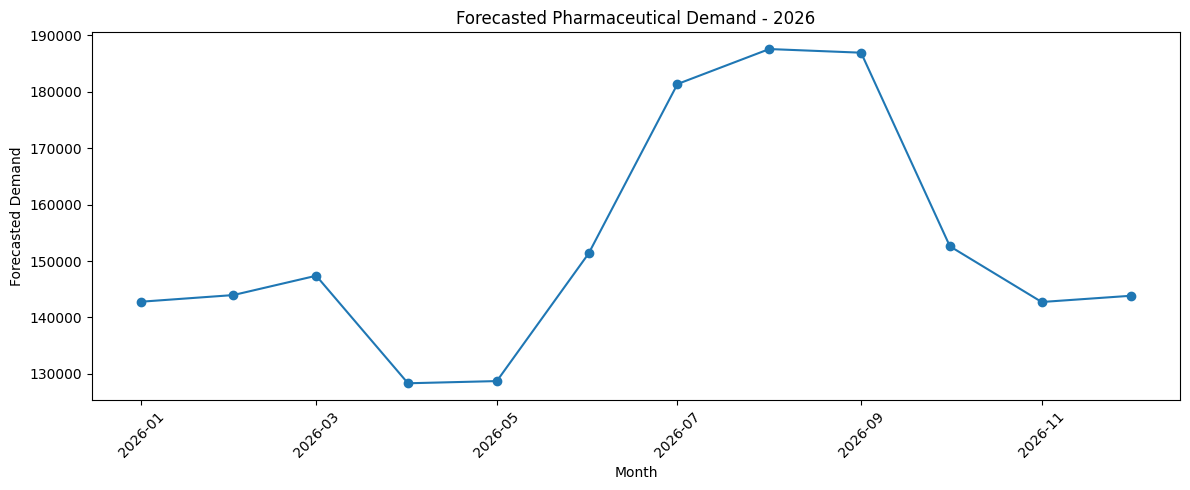

In [111]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_forecast["forecast_month"],
    monthly_forecast["forecast_demand"],
    marker="o"
)

plt.title("Forecasted Pharmaceutical Demand - 2026")
plt.xlabel("Month")
plt.ylabel("Forecasted Demand")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [112]:
top_forecasted_medicines = (
    forecast_df
    .groupby(
        [
            "product_id",
            "medicine_name",
            "category"
        ]
    )["forecast_demand"]
    .sum()
    .reset_index()
    .sort_values(
        "forecast_demand",
        ascending=False
    )
    .head(10)
)

top_forecasted_medicines

,product_id,medicine_name,category,forecast_demand
15,MED000016,Augmentin 265,Antibiotics,31830
13,MED000014,Dolo 650 661,Analgesics,31739
1,MED000002,Dolo 650,Respiratory,31608
16,MED000017,Azithromycin 865,Dermatology,31580
19,MED000020,Crocin 386,Analgesics,31529
10,MED000011,Cetirizine,Diabetes,31501
14,MED000015,Paracetamol 477,Neurology,31490
12,MED000013,Cetirizine 792,Analgesics,31387
7,MED000008,Cefixime,Diabetes,31375
17,MED000018,Metformin 836,Analgesics,31324


In [113]:
model_comparison.to_csv(
    f"{output_dir}/forecast_model_comparison.csv",
    index=False
)

In [114]:
top_forecasted_medicines.to_csv(
    f"{output_dir}/top_forecasted_medicines.csv",
    index=False
)

In [115]:
print("========== ML FORECASTING COMPLETE ==========")

print("\nSelected Model:")
print("Gradient Boosting Regressor")

print("\nForecast Records:")
print(len(forecast_df))

print("\nForecast Period:")
print(
    forecast_df["forecast_month"].min(),
    "to",
    forecast_df["forecast_month"].max()
)

print("\nOutput Files:")
print(os.listdir(output_dir))

print("\nModel Files:")
print(os.listdir(model_dir))

========== ML FORECASTING COMPLETE ==========

Selected Model:
Gradient Boosting Regressor

Forecast Records:
30000

Forecast Period:
2026-01-01 00:00:00 to 2026-12-01 00:00:00

Output Files:
['forecast_model_comparison.csv', 'inventory_recommendations.csv', 'medicine_demand_forecast_2026.csv', 'recommendation_summary.csv', 'top_forecasted_medicines.csv']

Model Files:
['gradient_boosting_demand_model.pkl']


In [116]:
print(
    "Unique forecast values:",
    forecast_df["forecast_demand"].nunique()
)

print(
    "Minimum forecast:",
    forecast_df["forecast_demand"].min()
)

print(
    "Maximum forecast:",
    forecast_df["forecast_demand"].max()
)

Unique forecast values: 177
Minimum forecast: 35
Maximum forecast: 4214


In [117]:
forecast_df["forecast_demand"].describe()

count    30000.000000
mean        61.255333
std        240.422993
min         35.000000
25%         40.000000
50%         40.000000
75%         43.000000
max       4214.000000
Name: forecast_demand, dtype: float64

In [118]:
(
    forecast_df
    .groupby(
        ["product_id", "medicine_name"]
    )["forecast_demand"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

product_id  medicine_name   
MED000016   Augmentin 265       31830
MED000014   Dolo 650 661        31739
MED000002   Dolo 650            31608
MED000017   Azithromycin 865    31580
MED000020   Crocin 386          31529
MED000011   Cetirizine          31501
MED000015   Paracetamol 477     31490
MED000013   Cetirizine 792      31387
MED000008   Cefixime            31375
MED000018   Metformin 836       31324
MED000009   Atorvastatin        31197
MED000010   Montelukast         31171
MED000006   Amoxicillin         31165
MED000003   Crocin              31155
MED000007   Pantoprazole        31116
MED000005   Azithromycin        31111
MED000012   Augmentin           31049
MED000019   Metformin 715       31049
MED000004   Metformin           31029
MED000001   Paracetamol         30557
Name: forecast_demand, dtype: int64

In [120]:
(
    forecast_df
    .groupby(
        ["product_id", "medicine_name"]
    )["forecast_demand"]
    .sum()
    .sort_values()
    .head(20)
)

product_id  medicine_name   
MED001141   Crocin 676          481
MED001234   Cefixime 196        481
MED001832   Dolo 650 596        482
MED002498   Crocin 806          482
MED000739   Crocin 87           482
MED001731   Metformin 132       482
MED001822   Cetirizine 209      482
MED001065   Atorvastatin 262    482
MED002084   Augmentin 689       482
MED000662   Montelukast 195     482
MED001865   Metformin 562       483
MED002381   Cetirizine 328      483
MED001351   Metformin 340       483
MED000596   Amoxicillin 408     483
MED001554   Cetirizine 433      483
MED002479   Atorvastatin 224    483
MED001703   Cefixime 472        483
MED001495   Metformin 432       483
MED000804   Paracetamol 673     483
MED001531   Dolo 650 311        483
Name: forecast_demand, dtype: int64

In [121]:
historical_summary = (
    monthly_demand
    .groupby("product_id")["demand"]
    .mean()
    .reset_index(name="historical_avg_monthly_demand")
)

forecast_summary = (
    forecast_df
    .groupby("product_id")["forecast_demand"]
    .mean()
    .reset_index(name="forecast_avg_monthly_demand")
)

forecast_check = historical_summary.merge(
    forecast_summary,
    on="product_id",
    how="inner"
)

forecast_check.head(20)

,product_id,historical_avg_monthly_demand,forecast_avg_monthly_demand
0,MED000001,2593.289855,2546.416667
1,MED000002,2578.608696,2634.000000
2,MED000003,2605.637681,2596.250000
3,MED000004,2631.666667,2585.750000
4,MED000005,2568.623188,2592.583333
5,MED000006,2577.072464,2597.083333
6,MED000007,2517.405797,2593.000000
7,MED000008,2547.115942,2614.583333
8,MED000009,2547.420290,2599.750000
9,MED000010,2636.188406,2597.583333


In [122]:
forecast_check.describe()

,historical_avg_monthly_demand,forecast_avg_monthly_demand
count,2500.000000,2500.000000
mean,61.056501,61.255333
std,228.306470,228.776127
min,15.000000,40.083333
25%,32.888889,40.666667
50%,39.465476,40.750000
75%,47.000000,40.750000
max,2741.623188,2652.500000
